# **RISE Insertion and Deletion bar charts**

This notebook generates bar charts for the Insertion and Deletion curves in the same style it is for IROF.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

Original Tie-Breaking


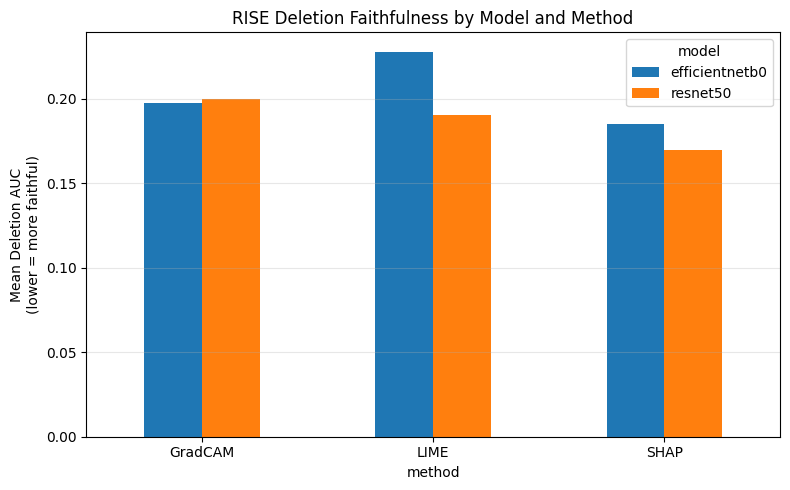

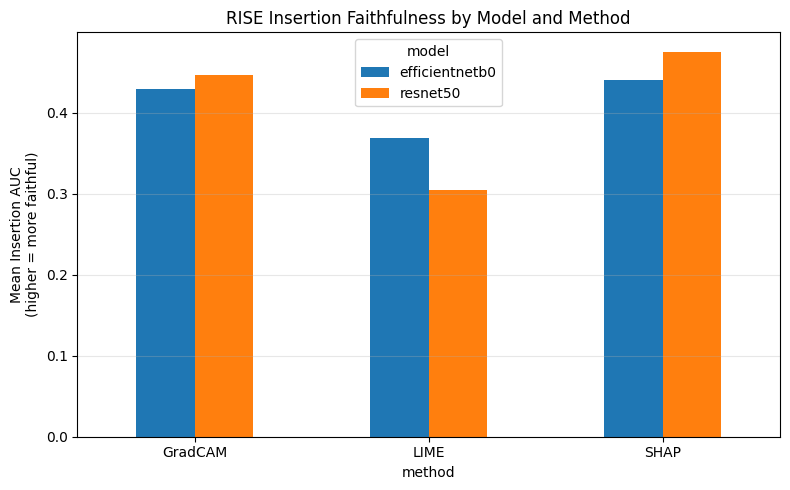

In [2]:
name = "aveera"
RESULTS_DIR = f"/data/{name}/results" # Where do you want to save these results
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

INCLUDE_RANDOM = False                              
METHOD_ORDER = ["GradCAM", "LIME", "SHAP"] + (["Random"] if INCLUDE_RANDOM else [])

RUNS = {
    "original": ("rise_original_summary.csv", "original tie-breaking"),
}

def bar_chart(summary, value_col, title, ylabel, save_path):
    """Draw a grouped bar chart, and save it as a PNG"""

    #Reshape the summary table so each row is a method and each column is a model
    pivot = (summary[summary["method"].isin(METHOD_ORDER)]
             .pivot(index="method", columns="model", values=value_col)
             .reindex(METHOD_ORDER))

    # Use matplotlib's default style
    with plt.style.context("default"):
        ax= pivot.plot(kind="bar", figsize=(8,5), rot=0)
        ax.set_xlabel("method")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend(title="model")
        ax.grid(axis="y",alpha=0.3)
        plt.tight_layout()
        plt.savefig(save_path,dpi=300,bbox_inches="tight")
        plt.show()
        plt.close()

# Make the plots for each RISE run
for tag, (csv_name, label) in RUNS.items():
    path = os.path.join(RESULTS_DIR, csv_name)

    # Skip this run if its summary file hasn't been generated yet
    if not os.path.exists(path):
        print(f"Skipping {tag}: {path} not found")
        continue
    summary = pd.read_csv(path)

    # Deletion AUC
    print(f"{label.title()}")
    bar_chart(summary, "del_auc",
                f"RISE Deletion Faithfulness by Model and Method",
                "Mean Deletion AUC\n(lower = more faithful)",
                os.path.join(FIGURES_DIR, f"rise_{tag}_deletion_bars.png"))
    # Insertion AUC
    bar_chart(summary, "ins_auc",
                f"RISE Insertion Faithfulness by Model and Method",
                "Mean Insertion AUC\n(higher = more faithful)",
                os.path.join(FIGURES_DIR, f"rise_{tag}_insertion_bars.png"))